# Practice #3. "Dynamic predictive models"

Stationarity, differencing, autocorrelation, AR forecasting and SSA.

Fill in the cells tagged `graded`, keeping every name and signature exactly as
given — they are graded automatically.

**Two series below, not interchangeable:**
- `demo_stationary`, `demo_random_walk` — short seeded synthetic series, used
  only to show what each test responds to.
- `series` — the real Melbourne temperatures. "Your series" always means this.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import acf, adfuller, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

def find_data_dir():
    """The repo's data/ directory, wherever the kernel happens to start."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "data" / "airline-passengers.csv").exists():
            return folder / "data"
    raise FileNotFoundError("data/ not found - run this notebook inside the repo")


DATA_DIR = globals().get("DATA_DIR", find_data_dir())
RANDOM_SEED = 42

## 0. Data

In [2]:
def load_series(path, time_col, value_col):
    """Read a CSV into a float Series named "y" on a DatetimeIndex."""
    # Сначала выбираю только нужные колонки, чтобы dropna случайно не выкинул строки из-за пропусков в других столбцах
    df = pd.read_csv(path, usecols=[time_col, value_col])
    df[time_col] = pd.to_datetime(df[time_col])
    df[value_col] = pd.to_numeric(df[value_col], errors="coerce")
    # Удаляю пропуски и сортирую по времени, чтобы индекс был монотонным
    df = df.dropna(subset=[time_col, value_col]).sort_values(time_col)
    return df.set_index(time_col)[value_col].astype(float).rename("y")

3650 points, 1981-01-01 to 1990-12-31


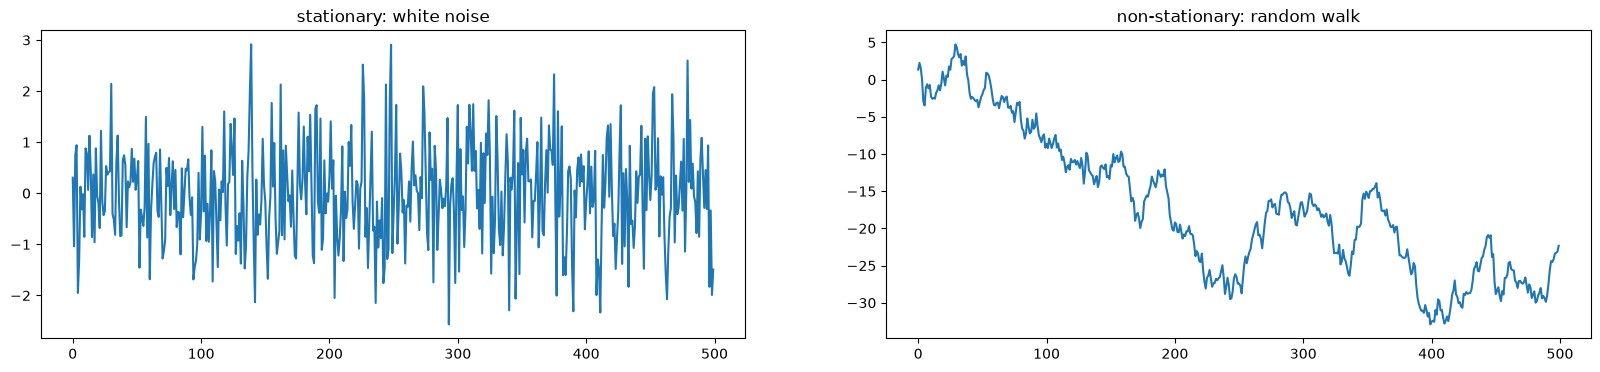

In [3]:
series = load_series(DATA_DIR / "daily-min-temperatures.csv", "Date", "Temp")
print(f"{len(series)} points, {series.index.min():%Y-%m-%d} to {series.index.max():%Y-%m-%d}")

rng = np.random.default_rng(RANDOM_SEED)
demo_stationary = pd.Series(rng.normal(0, 1, 500))
demo_random_walk = pd.Series(rng.normal(0, 1, 500).cumsum())

fig, axes = plt.subplots(1, 2, figsize=(20, 4))
demo_stationary.plot(ax=axes[0], title="stationary: white noise")
demo_random_walk.plot(ax=axes[1], title="non-stationary: random walk");

## 1. Stationarity and the Dickey-Fuller test

A series is stationary when its mean, variance and autocovariance do not depend
on *when* you look. AR, MA and ARMA all assume it.

ADF's null is **"there is a unit root"** — non-stationary. So a **small**
p-value rejects the null and means *stationary*. Inverting this is the most
common error in this practice.

In [4]:
def adf_test(series, significance=0.05):
    """Augmented Dickey-Fuller test.

    Returns {"statistic", "p_value", "used_lag", "n_obs", "critical_values"
    (dict), "is_stationary" (bool)}.

    ADF's null is "has a unit root" = non-stationary. Small p => stationary.
    """
    # Запускаю тест Дики-Фуллера и распаковываю кортеж результатов
    res = adfuller(series)
    stat, p_value, used_lag, n_obs, critical_values = res[:5]
    # Привожу типы к обычным Python float/int/bool, чтобы не было сюрпризов с numpy-скалярами
    return {
        "statistic": float(stat),
        "p_value": float(p_value),
        "used_lag": int(used_lag),
        "n_obs": int(n_obs),
        "critical_values": {k: float(v) for k, v in critical_values.items()},
        "is_stationary": bool(p_value < significance),
    }

In [5]:
for name, candidate in (("white noise", demo_stationary),
                        ("random walk", demo_random_walk),
                        ("temperatures", series)):
    result = adf_test(candidate)
    verdict = "stationary" if result["is_stationary"] else "NON-stationary"
    print(f"{name:>14}: p = {result['p_value']:.2e}  ->  {verdict}")

   white noise: p = 0.00e+00  ->  stationary
   random walk: p = 2.67e-01  ->  NON-stationary
  temperatures: p = 2.47e-04  ->  stationary


C:\Users\fedor\AppData\Local\Temp\ipykernel_7624\869394941.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)
C:\Users\fedor\AppData\Local\Temp\ipykernel_7624\869394941.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)
C:\Users\fedor\AppData\Local\Temp\ipykernel_7624\869394941.py:10: FutureWarning: adfuller currently retu

### 1.1 Differencing

Replacing `y[t]` with `y[t] - y[t-1]` removes a unit root. One difference
usually kills a linear trend, two handle a quadratic one. Over-differencing adds
noise, so stop as soon as the test agrees.

Practice 4 reuses this: the number of differences is the `d` in ARIMA(p, d, q).

In [6]:
def difference(series, periods=1):
    """Difference, then drop the NaNs the shift introduces."""
    # Считаю разности с лагом periods и сразу убираю появившиеся в начале NaN
    return series.diff(periods).dropna()


def make_stationary(series, max_diff=2, significance=0.05):
    """Difference until ADF calls the series stationary.

    Returns (series, n_differences). Already stationary => unchanged, 0.
    Stop at `max_diff` and return what you have even if ADF still refuses.
    """
    current = series
    n_differences = 0
    # Дифференцирую по шагам, пока ADF не скажет, что ряд стационарен, или не упремся в max_diff
    while n_differences < max_diff and not adf_test(current, significance=significance)["is_stationary"]:
        current = difference(current, periods=1)
        n_differences += 1
    return current, n_differences

In [7]:
walk_stationary, n_diffs = make_stationary(demo_random_walk)
print(f"random walk needed {n_diffs} difference(s); "
      f"p-value now {adf_test(walk_stationary)['p_value']:.2e}")

series_stationary, series_diffs = make_stationary(series)
print(f"temperatures needed {series_diffs} difference(s)")

C:\Users\fedor\AppData\Local\Temp\ipykernel_7624\869394941.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)
C:\Users\fedor\AppData\Local\Temp\ipykernel_7624\869394941.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)
C:\Users\fedor\AppData\Local\Temp\ipykernel_7624\869394941.py:10: FutureWarning: adfuller currently retu

random walk needed 1 difference(s); p-value now 0.00e+00


temperatures needed 0 difference(s)


C:\Users\fedor\AppData\Local\Temp\ipykernel_7624\869394941.py:10: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series)


**Question.** The series has a strong yearly cycle, yet ADF calls it
stationary with zero differences. Is a seasonal series stationary? What is ADF
sensitive to, and what does it ignore?

**Ответ.** Формально сезонный ряд не является строго стационарным, потому что его математическое ожидание периодически меняется в течение года (зимой температура ниже, летом выше — средняя зависит от времени года). Однако тест ADF проверяет только наличие **единичного корня** (стохастического тренда / случайного блуждания, когда ряд уходит всё дальше без возврата к среднему). Поскольку амплитуда и уровень годового цикла стабильны во времени и ряд регулярно возвращается к одному и тому же сезонному профилю ($p = 2.47 \times 10^{-4} < 0.05$), ADF отвергает гипотезу о единичном корне и не требует дифференцирования, игнорируя детерминированную периодическую сезонность.

## 2. Autocorrelation analysis

- **ACF** at lag k — correlation of `y[t]` with `y[t-k]`, everything in between
  included.
- **PACF** at lag k — the same, with the intermediate lags partialled out.

Rule of thumb for Practice 4: PACF cuts off after lag p => AR(p); ACF cuts off
after lag q => MA(q).

In [8]:
def acf_values(series, nlags):
    """Autocorrelations, lags 0..nlags, as a 1-D numpy array."""
    # Вычисляю ACF для лагов от 0 до nlags и привожу к 1-D массиву float
    return np.asarray(acf(series, nlags=nlags), dtype=float)


def pacf_values(series, nlags):
    """Partial autocorrelations, lags 0..nlags, as a 1-D numpy array."""
    # То же самое для частной автокорреляции PACF
    return np.asarray(pacf(series, nlags=nlags), dtype=float)

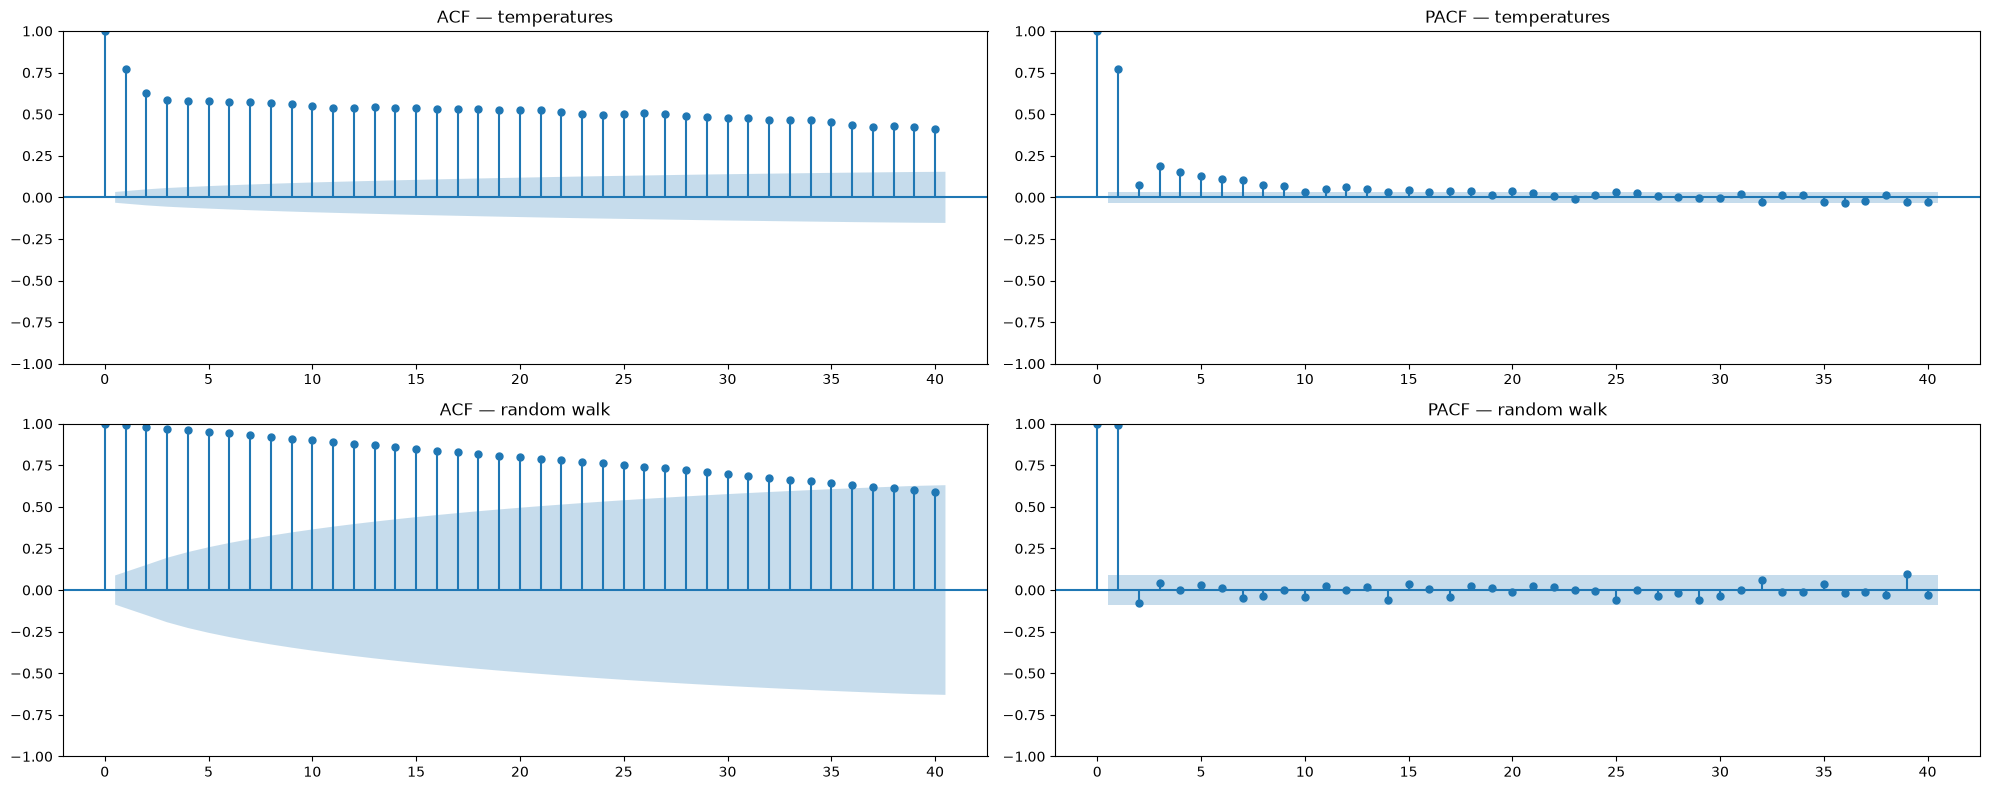

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(20, 8))
plot_acf(series, lags=40, ax=axes[0, 0], title="ACF — temperatures")
plot_pacf(series, lags=40, ax=axes[0, 1], title="PACF — temperatures")
plot_acf(demo_random_walk, lags=40, ax=axes[1, 0], title="ACF — random walk")
plot_pacf(demo_random_walk, lags=40, ax=axes[1, 1], title="PACF — random walk")
plt.tight_layout();

In [10]:
pacf_temps = pacf_values(series, 10)
print("PACF lags 1..10:", np.round(pacf_temps[1:], 3))
print("\nlags whose |PACF| exceeds the 95% band:",
      [lag for lag in range(1, 11)
       if abs(pacf_temps[lag]) > 1.96 / np.sqrt(len(series))])

PACF lags 1..10: [0.774 0.077 0.189 0.152 0.13  0.11  0.103 0.075 0.07  0.036]

lags whose |PACF| exceeds the 95% band: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


**Question.** The random walk's ACF decays slowly while its PACF cuts
off after lag 1. What does that pattern mean, and how does one difference change
it?

**Ответ.** Медленно затухающая ACF у случайного блуждания означает, что $y_t$ сильно коррелирует даже с далёкими прошлыми значениями, так как все случайные шаги накапливаются ($y_t = y_{t-1} + \varepsilon_t$). При этом PACF резко обрывается после лага 1 (на лаге 1 она близка к $1$, а на лагах $\ge 2$ около нуля), потому что вся зависимость $y_t$ от $y_{t-2}, y_{t-3}, \dots$ полностью передаётся через $y_{t-1}$ — если зафиксировать предыдущее значение, более ранние лаги ничего нового не добавляют. После взятия первой разности ($y_t - y_{t-1} = \varepsilon_t$) ряд превращается в белый шум: и ACF, и PACF на всех лагах $k \ge 1$ становятся близки к нулю и лежат в пределах 95%-й доверительной полосы.

## 3. Forecasting with an AR model

AR(p) regresses `y[t]` on its own previous p values. Pick p from the PACF plot
above, then forecast the held-out year.

In [11]:
def ar_forecast(train, index, lags):
    """Fit AutoReg(lags) on `train`, forecast over `index`."""
    # Обучаю AutoReg только на train (передаю значения массивом, чтобы не было предупреждений про freq индекса)
    model = AutoReg(np.asarray(train, dtype=float), lags=lags).fit()
    preds = np.asarray(model.forecast(len(index)), dtype=float)
    # Оборачиваю прогноз в Series с нужным индексом и именем "y"
    return pd.Series(preds, index=index, name="y")

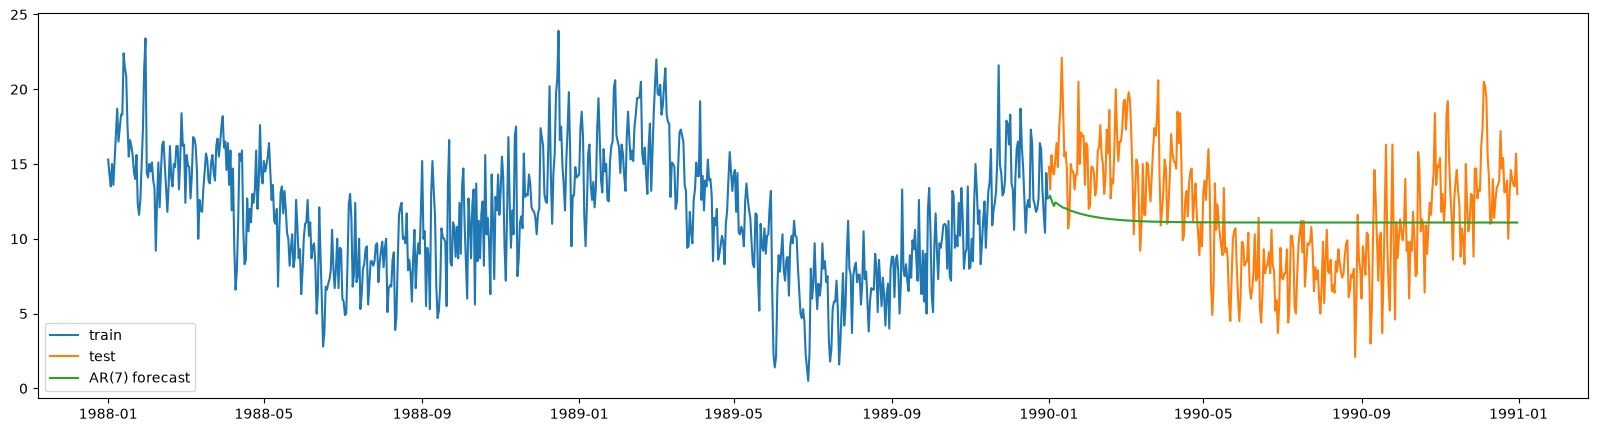

AR(7) RMSE: 3.7902


In [12]:
train, test = series.iloc[:-365], series.iloc[-365:]
forecast = ar_forecast(train, test.index, lags=7)

plt.figure(figsize=(20, 5))
plt.plot(train.iloc[-730:], label="train")
plt.plot(test, label="test")
plt.plot(forecast, label="AR(7) forecast")
plt.legend()
plt.show()

error = np.sqrt(np.mean((test.to_numpy() - forecast.to_numpy()) ** 2))
print(f"AR(7) RMSE: {error:.4f}")

**Question.** The forecast flattens after a few steps. Why does a pure
AR model converge to the series mean, and what does that mean for a 365-day
horizon?

**Ответ.** У стационарной модели AR($p$) все корни характеристического уравнения лежат вне единичного круга, поэтому при рекурсивном прогнозировании вперёд влияние последних наблюдаемых точек экспоненциально затухает. Через несколько недель прогноз сходится к безусловному среднему обучающей выборки ($\approx 11.12\,^\circ\text{C}$). Для горизонта в 365 дней это означает, что чистая модель AR(7) без сезонной компоненты или экзогенных признаков не способна воспроизвести годовой цикл температур и на длинной дистанции вырождается в плоскую прямую (из-за чего ошибка на тестовом годе составляет $\text{RMSE} \approx 3.79\,^\circ\text{C}$).

## 4. Singular Spectrum Analysis (SSA)

Decomposes a series without assuming a model. Three steps:

1. **Embed** — stack lagged windows of length L into a trajectory matrix.
2. **Decompose** — SVD; each singular triple gives one elementary matrix.
3. **Reconstruct** — sum the elementary matrices you want, then average the
   anti-diagonals back into a series (*diagonal averaging*).

The SVD is exact, so summing **all** components must return the original series.
The tests check that, and so should you while debugging.

In [13]:
def trajectory_matrix(series, window_length):
    """Hankel matrix of lagged windows — step 1 of SSA.

    N points, window L -> an (L, K) matrix, K = N - L + 1, column k being
    series[k : k + L].
    """
    values = np.asarray(series, dtype=float)
    n_points = len(values)
    n_columns = n_points - window_length + 1
    if n_columns < 1:
        raise ValueError("window_length must not exceed len(series)")
    return np.column_stack([values[k:k + window_length] for k in range(n_columns)])

In [14]:
def diagonal_average(matrix):
    """Average the anti-diagonals of an (L, K) matrix back into a series.

    Element i is the mean of every matrix[r, c] with r + c == i.
    Result length is L + K - 1.
    """
    mat = np.asarray(matrix, dtype=float)
    n_rows, n_cols = mat.shape
    # Отражаю матрицу по горизонтали: тогда побочные диагонали (r + c == i) становятся обычными диагоналями
    flipped = np.fliplr(mat)
    # Для каждого i от 0 до L + K - 2 смещение диагонали равно (K - 1) - i
    return np.array(
        [np.mean(np.diagonal(flipped, offset=n_cols - 1 - i)) for i in range(n_rows + n_cols - 1)],
        dtype=float,
    )


def ssa_reconstruct(series, window_length, indices):
    """Reconstruct a series from the SSA components in `indices`."""
    # Шаг 1: строю матрицу траекторий (L x K)
    traj = trajectory_matrix(series, window_length)
    # Шаг 2: делаю сингулярное разложение (SVD)
    u, s, vt = np.linalg.svd(traj, full_matrices=False)
    idx = list(indices)
    if len(idx) == 0:
        reconstructed_matrix = np.zeros_like(traj)
    else:
        # Шаг 3: суммирую только выбранные элементарные матрицы U[:, i] * s[i] * Vt[i, :]
        reconstructed_matrix = (u[:, idx] * s[idx]) @ vt[idx, :]
    # Усредняю антидиагонали обратно в одномерный ряд
    rec = diagonal_average(reconstructed_matrix)
    if isinstance(series, pd.Series):
        return pd.Series(rec, index=series.index, name=series.name)
    return rec

max |original - full reconstruction| = 4.33e-13


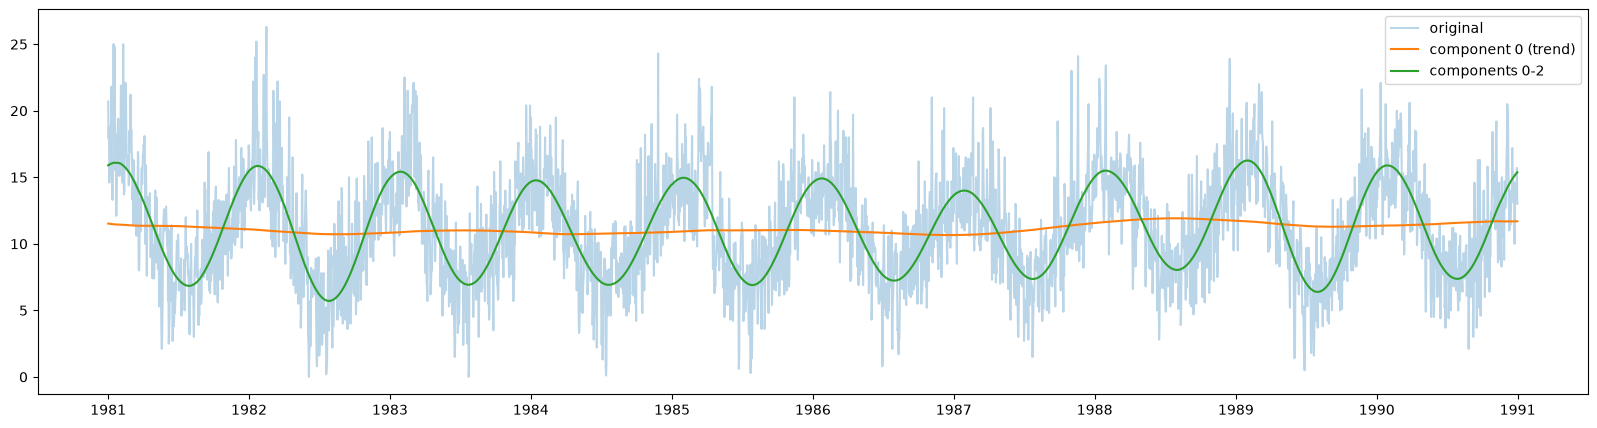

In [15]:
window = 365
full = ssa_reconstruct(series, window, range(min(window, len(series) - window + 1)))
print(f"max |original - full reconstruction| = {float((series - full).abs().max()):.2e}")

trend_component = ssa_reconstruct(series, window, [0])
seasonal_component = ssa_reconstruct(series, window, [1, 2])

plt.figure(figsize=(20, 5))
plt.plot(series, alpha=0.3, label="original")
plt.plot(trend_component, label="component 0 (trend)")
plt.plot(trend_component + seasonal_component, label="components 0-2")
plt.legend();

Pick L between N/4 and N/3, plot the singular values, and decide how
many components carry signal rather than noise.

**Question.** Components 1 and 2 usually arrive as a pair with nearly equal
singular values. What structure produces a *pair*, and why can one component
alone not represent it?

**Ответ.** Пара компонент с почти равными сингулярными значениями ($\sigma_1 \approx 2303.13$ и $\sigma_2 \approx 2300.77$ при $L = 365$) соответствует **периодическому гармоническому колебанию** — в данном случае годовому циклу температуры. Одна компонента ранга 1 способна задать колебание только с одной фиксированной фазой, но при сдвиге окна в матрице траекторий фаза меняется. Чтобы описать синусоиду с произвольным сдвигом фазы, нужен базис из двух ортогональных функций — синуса и косинуса одной частоты, поэтому гармоника занимает двумерное подпространство и даёт пару компонент с близкими сингулярными значениями. На логарифмическом графике спектра видно, что основной сигнал сосредоточен в компонентах 0–2 (тренд и годовая гармоника) и слабой второй гармонике (пара 3–4 со значениями $\approx 434$ и $411$), а начиная с 5-й компоненты начинается пологое плато шума.

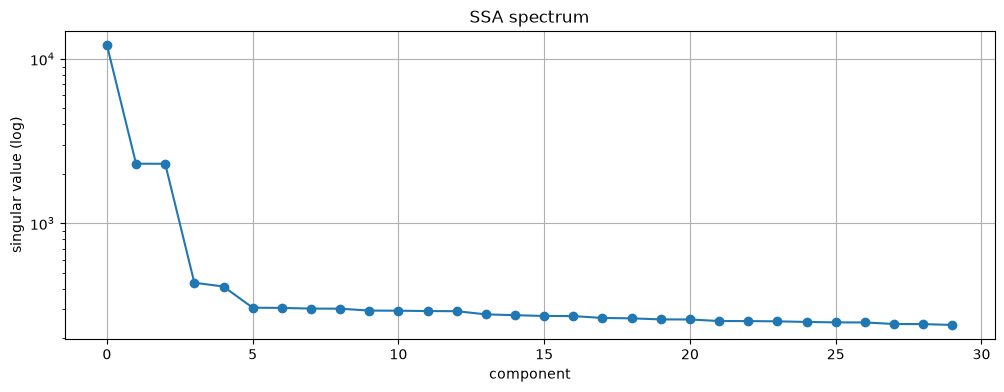

In [16]:
matrix = trajectory_matrix(series, window)
singular_values = np.linalg.svd(matrix, compute_uv=False)

plt.figure(figsize=(12, 4))
plt.semilogy(singular_values[:30], "o-")
plt.xlabel("component")
plt.ylabel("singular value (log)")
plt.title("SSA spectrum")
plt.grid(True);

AR( 1) RMSE = 3.8828, последнее значение прогноза = 11.112
AR( 3) RMSE = 3.8706, последнее значение прогноза = 11.102
AR( 7) RMSE = 3.7902, последнее значение прогноза = 11.087
AR(14) RMSE = 3.6827, последнее значение прогноза = 11.019
AR(30) RMSE = 3.6354, последнее значение прогноза = 11.021



Первые 8 сингулярных значений при L=1000: [18042.91  3373.97  3195.31   545.26   528.67   412.38   400.17   340.17]


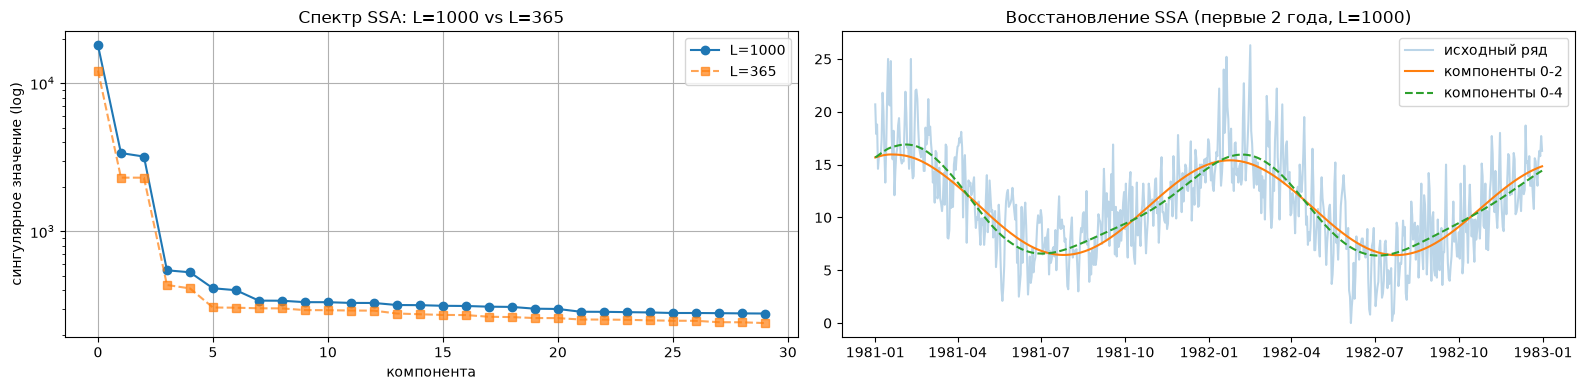

In [17]:
# Свободное исследование: сравню разные порядки AR(p) и выбор длины окна L в SSA (между N/4 и N/3)

# 1. Сравнение AR(p) для разных p на тестовом годе
for p_lag in [1, 3, 7, 14, 30]:
    fc = ar_forecast(train, test.index, lags=p_lag)
    rmse_p = np.sqrt(np.mean((test.to_numpy() - fc.to_numpy()) ** 2))
    print(f"AR({p_lag:2d}) RMSE = {rmse_p:.4f}, последнее значение прогноза = {fc.iloc[-1]:.3f}")

# 2. Спектр сингулярных значений при L между N/4 и N/3 (N=3650 -> берем L=1000)
L_alt = 1000
s_alt = np.linalg.svd(trajectory_matrix(series, L_alt), compute_uv=False)
print("\nПервые 8 сингулярных значений при L=1000:", np.round(s_alt[:8], 2))

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
axes[0].semilogy(s_alt[:30], "o-", label="L=1000")
axes[0].semilogy(singular_values[:30], "s--", alpha=0.7, label="L=365")
axes[0].set_title("Спектр SSA: L=1000 vs L=365")
axes[0].set_xlabel("компонента")
axes[0].set_ylabel("сингулярное значение (log)")
axes[0].legend()
axes[0].grid(True)

# Сравниваю восстановление только по 0..2 и с добавлением второй гармоники 3..4
rec_02 = ssa_reconstruct(series, L_alt, [0, 1, 2])
rec_04 = ssa_reconstruct(series, L_alt, [0, 1, 2, 3, 4])
axes[1].plot(series.iloc[:730], alpha=0.3, label="исходный ряд")
axes[1].plot(rec_02.iloc[:730], label="компоненты 0-2")
axes[1].plot(rec_04.iloc[:730], "--", label="компоненты 0-4")
axes[1].set_title("Восстановление SSA (первые 2 года, L=1000)")
axes[1].legend()
plt.tight_layout();